# Deception Detection in Model-Free NE Seeking — Numerical Validation

Companion notebook to *Detecting and Recovering from Deception in Model-Free Nash-Equilibrium
Seeking: A Dual-Demodulation Analysis*.

Everything below integrates the **true time-varying system**, never the averaged one — the
averaged system would satisfy the identities exactly and prove nothing.

| § | Claim under test | Where in the paper |
|---|---|---|
| 1 | DNE exists; $\partial_vJ_v(u^*)=-\delta^*\partial_dJ_v(u^*)$ | Def. 1, eq. $(\star)$ |
| 2 | $C_v$ is blind; action residual $r_v$ also fails | Lemma 2 |
| 3 | $C_v=\partial_vJ_v+\delta\partial_dJ_v$, $C_v'=\partial_vJ_v$ | Lemma 1(a),(b) |
| 4 | $D_v=|\delta||\partial_dJ_v|$ at **every** $t$; threshold separation | Thm 1, Cor. 1 |
| 5 | Washout is necessary; its gain must be compensated | Rem. 1, Rem. 3 |
| 6 | Residual $\eta\sim C_1a^2+C_2(k/a\omega)^2$ — **not** monotone in $a$ | Rem. 4 |
| 7 | Finite window: $1/\omega\ll T\ll 1/k$ | Rem. 5 |
| 8 | Behaviour under measurement noise (ROC) | Rem. 5 |
| 9 | Non-quadratic game — exercises the third-order remainder $R_2$ | Lemma 1 proof |
| 10 | Assumption 3 boundary: $\partial_dJ_v\to0$ | Assum. 3 |
| 11 | Assumption 2: near-resonant probe selection | Assum. 2 |
| 12 | Recovery by frequency switch | Thm 2 |
| 13 | Robustness over initial conditions and $J_d^{\mathrm{ref}}$ | — |

In [1]:
import numpy as np, matplotlib.pyplot as plt
from math import sin
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':0.3,'font.size':9})
RESULTS = {}

## 0. Core integrator and demodulator

In [2]:
def simulate(game, a=0.05, k=0.30, eps=0.08, wv=None, wd=None, wvp=None, wh=None,
             Jd_ref=0.15, dt=1e-3, Tend=300.0, deceptive=True, dual_probe=True,
             washout=True, u0=(0.2, 0.2), switch_t=None, wv_new=None):
    """RK4 integration of the true time-varying system.

    xv = uv + a sin(wu t) [+ a sin(wvp t)]           wu = wv, or wv_new after switch_t
    xd = ud + a sin(wd t) + a delta sin(wv t)        deceiver always injects at wv
    washout:  zdot = -wh (z - J),  h = J - z
    update :  uvdot = -(2k/a) hv sin(wu t),  uddot = -(2k/a) hd sin(wd t)
    deceiver: deltadot = eps (Jd - Jd_ref)
    """
    Jv, Jd = game['Jv'], game['Jd']
    n = int(Tend/dt)
    s = [u0[0], u0[1], 0.0, 0.0, 0.0]          # uv, ud, delta, zv, zd
    U = np.zeros((n, 3)); HV = np.zeros(n); XV = np.zeros(n); XD = np.zeros(n)
    ts = np.arange(n)*dt
    K = [[0.0]*5 for _ in range(4)]
    for i in range(n):
        t0 = ts[i]
        U[i, 0], U[i, 1], U[i, 2] = s[0], s[1], s[2]
        for stage, hh in enumerate((0.0, 0.5, 0.5, 1.0)):
            tt = t0 + hh*dt
            if stage == 0:
                p = s
            else:
                src = K[stage-1]
                p = [s[j] + hh*dt*src[j] for j in range(5)]
            wu = wv_new if (switch_t is not None and tt >= switch_t) else wv
            xv = p[0] + a*sin(wu*tt) + (a*sin(wvp*tt) if dual_probe else 0.0)
            xd = p[1] + a*sin(wd*tt) + (a*p[2]*sin(wv*tt) if deceptive else 0.0)
            jv, jd = Jv(xv, xd), Jd(xv, xd)
            hv = jv - p[3] if washout else jv
            hd = jd - p[4] if washout else jd
            K[stage][0] = -(2*k/a)*hv*sin(wu*tt)
            K[stage][1] = -(2*k/a)*hd*sin(wd*tt)
            K[stage][2] = eps*(jd - Jd_ref) if deceptive else 0.0
            K[stage][3] = -wh*(p[3] - jv)
            K[stage][4] = -wh*(p[4] - jd)
            if stage == 0:
                HV[i], XV[i], XD[i] = hv, xv, xd
        for j in range(5):
            s[j] += (dt/6)*(K[0][j] + 2*K[1][j] + 2*K[2][j] + K[3][j])
        if not np.isfinite(s[0]) or abs(s[0]) > 1e4:      # divergence guard
            m = i + 1
            return dict(t=ts[:m], U=U[:m], H=HV[:m], xv=XV[:m], xd=XD[:m], diverged=True)
    return dict(t=ts, U=U, H=HV, xv=XV, xd=XD, diverged=False)


def Gamma(w, wh):
    """Washout retention factor for a demodulation at the same frequency w."""
    return w*w/(w*w + wh*wh)


def demod(t, H, w, a, wh, Twin, compensate=True):
    """(2 / (a*Gamma)) * (1/T) int_{t-T}^t H(tau) sin(w tau) dtau, as a sliding window."""
    dt = t[1] - t[0]
    m = int(round(Twin/dt))
    cs = np.concatenate(([0.0], np.cumsum(H*np.sin(w*t))*dt))
    out = np.full_like(t, np.nan)
    g = Gamma(w, wh) if compensate else 1.0
    out[m:] = (2.0/(a*g))*(cs[m+1:len(t)+1] - cs[1:len(t)-m+1])/Twin
    return out

### Games and default configuration

In [3]:
def quadratic(c=0.3, e=0.5):
    """Strongly monotone quadratic game. d3J = 0, so it does NOT exercise R2."""
    return dict(
        name=f'quadratic(c={c}, e={e})',
        Jv=lambda xv, xd: 0.5*(xv-1)**2 + c*xv*xd + e*xd,
        Jd=lambda xv, xd: 0.5*(xd-1)**2 + c*xv*xd,
        dvJv=lambda xv, xd: (xv-1) + c*xd,
        ddJv=lambda xv, xd: c*xv + e,
        ddJd=lambda xv, xd: (xd-1) + c*xv)

def cubic(c=0.3, e=0.5, q=0.4):
    """Non-quadratic: d3Jv/dxv3 = 2q != 0, so the third-order remainder is active."""
    return dict(
        name=f'cubic(c={c}, e={e}, q={q})',
        Jv=lambda xv, xd: 0.5*(xv-1)**2 + c*xv*xd + e*xd + (q/3.0)*xv**3,
        Jd=lambda xv, xd: 0.5*(xd-1)**2 + c*xv*xd,
        dvJv=lambda xv, xd: (xv-1) + c*xd + q*xv**2,
        ddJv=lambda xv, xd: c*xv + e,
        ddJd=lambda xv, xd: (xd-1) + c*xv)

def weakly_coupled(e):
    """ddJv = e is constant: e -> 0 makes deception ineffective (Assumption 3 boundary)."""
    return dict(
        name=f'weakly_coupled(e={e})',
        Jv=lambda xv, xd: 0.5*(xv-1)**2 + e*xd,
        Jd=lambda xv, xd: 0.5*(xd-1)**2 + 0.3*xv*xd,
        dvJv=lambda xv, xd: (xv-1),
        ddJv=lambda xv, xd: e + 0.0*xv,
        ddJd=lambda xv, xd: (xd-1) + 0.3*xv)

def true_NE(game, guess=(0.7, 0.7)):
    """Solve Ghon(u) = 0 by damped Newton on the honest pseudogradient."""
    from scipy.optimize import fsolve
    F = lambda u: [game['dvJv'](u[0], u[1]), game['ddJd'](u[0], u[1])]
    return np.array(fsolve(F, guess))

TWOPI = 2*np.pi
CFG = dict(a=0.05, k=0.30, eps=0.08, wv=TWOPI*5.0, wd=TWOPI*7.3, wvp=TWOPI*11.7,
           wh=TWOPI*1.0, Jd_ref=0.15, dt=1e-3, Tend=300.0)
TWIN = 10.0
DELTA_MIN, C0 = 0.10, 0.60
RHO = 0.5*DELTA_MIN*C0

G = quadratic()
u_star = true_NE(G)
print(f"game: {G['name']}")
print(f"true NE  u* = ({u_star[0]:.4f}, {u_star[1]:.4f})")
print(f"threshold rho = {RHO}")

game: quadratic(c=0.3, e=0.5)
true NE  u* = (0.7692, 0.7692)
threshold rho = 0.03


## 1. The deceptive equilibrium exists and is where the theory says

Runs the honest system ($\delta_d\equiv0$) and the deceptive system side by side.
Checks the three DNE conditions of Definition 1 and the key identity
$|\partial_vJ_v(u^*)| = |\delta^*_d||\partial_dJ_v(u^*)|$.

honest    uv=0.7612  ud=0.7740   |uv-uv*| = 8.01e-03
deceptive uv=0.5455  ud=0.8375  delta*  = 0.2976

Definition 1 conditions at the DNE:
  perceived gradient  dvJv + delta*ddJv = -0.00575   (should be 0)
  deceiver stationary ddJd            = +0.00113   (should be 0)
  payoff target       Jd              = 0.15025   (target 0.15)

identity (*)  |dvJv(u*)| = 0.20328   |delta*||ddJv(u*)| = 0.19753   rel.err 2.91%

victim payoff  honest 0.5922 -> DNE 0.6591  (worse)
deceiver payoff honest 0.2023 -> DNE 0.1503  (better)


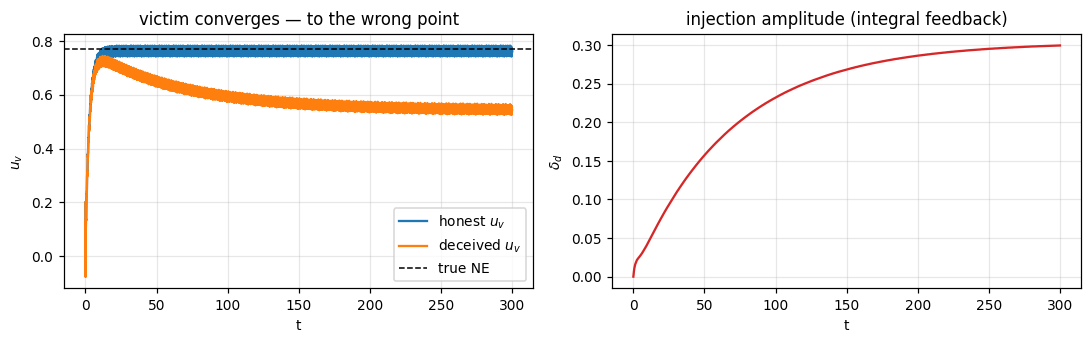

In [4]:
run_h = simulate(G, deceptive=False, **CFG)
run_d = simulate(G, deceptive=True,  **CFG)
t = run_d['t']
tail = t > 0.85*CFG['Tend']

mh, md_ = run_h['U'][tail].mean(0), run_d['U'][tail].mean(0)
dvJv, ddJv, ddJd = G['dvJv'], G['ddJv'], G['ddJd']

print(f"honest    uv={mh[0]:.4f}  ud={mh[1]:.4f}   |uv-uv*| = {abs(mh[0]-u_star[0]):.2e}")
print(f"deceptive uv={md_[0]:.4f}  ud={md_[1]:.4f}  delta*  = {md_[2]:.4f}")
print()
print("Definition 1 conditions at the DNE:")
print(f"  perceived gradient  dvJv + delta*ddJv = "
      f"{dvJv(*md_[:2]) + md_[2]*ddJv(*md_[:2]):+.5f}   (should be 0)")
print(f"  deceiver stationary ddJd            = {ddJd(*md_[:2]):+.5f}   (should be 0)")
print(f"  payoff target       Jd              = {G['Jd'](*md_[:2]):.5f}   "
      f"(target {CFG['Jd_ref']})")
print()
lhs, rhs = abs(dvJv(*md_[:2])), abs(md_[2])*abs(ddJv(*md_[:2]))
print(f"identity (*)  |dvJv(u*)| = {lhs:.5f}   |delta*||ddJv(u*)| = {rhs:.5f}   "
      f"rel.err {abs(lhs-rhs)/rhs:.2%}")
print()
print(f"victim payoff  honest {G['Jv'](*mh[:2]):.4f} -> DNE {G['Jv'](*md_[:2]):.4f}  (worse)")
print(f"deceiver payoff honest {G['Jd'](*mh[:2]):.4f} -> DNE {G['Jd'](*md_[:2]):.4f}  (better)")

RESULTS['DNE'] = dict(delta=md_[2], uv=md_[0], ident_relerr=abs(lhs-rhs)/rhs)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(t, run_h['U'][:, 0], label='honest $u_v$')
ax[0].plot(t, run_d['U'][:, 0], label='deceived $u_v$')
ax[0].axhline(u_star[0], ls='--', c='k', lw=1, label='true NE')
ax[0].set_xlabel('t'); ax[0].set_ylabel('$u_v$'); ax[0].legend()
ax[0].set_title('victim converges — to the wrong point')
ax[1].plot(t, run_d['U'][:, 2], c='C3'); ax[1].set_xlabel('t')
ax[1].set_ylabel(r'$\delta_d$'); ax[1].set_title('injection amplitude (integral feedback)')
plt.tight_layout(); plt.show()

## 2. Lemma 2 — the raw signal is blind, and so is the action residual

Two things must be shown:

1. $|C_v|$ converges to the same value in both regimes, so no threshold on $C_v$ can work.
2. The action residual $r_v = u_v(t+\Delta) - [u_v(t) - k\Delta\,C_v(t)]$ vanishes in both
   regimes — the victim *does* obey the honest update rule, only its input is corrupted.

|Cv| steady   honest 5.55e-13    deceptive 2.21e-04
  both are far below the threshold rho = 0.03: neither regime can be flagged.
  for contrast, the true gradient at the DNE is 0.2033 -- large, and invisible to Cv.

action residual r_v   honest 1.58e-02    deceptive 1.45e-02   -> also blind


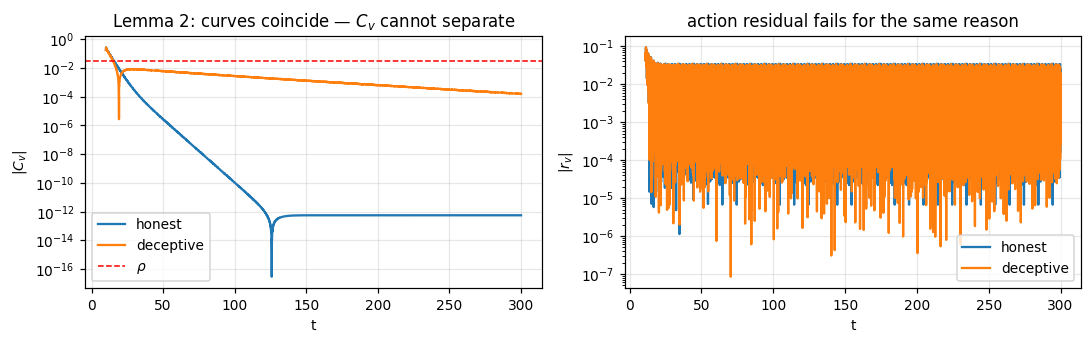

In [5]:
Cv_h  = demod(t, run_h['H'], CFG['wv'],  CFG['a'], CFG['wh'], TWIN)
Cvp_h = demod(t, run_h['H'], CFG['wvp'], CFG['a'], CFG['wh'], TWIN)
Cv_d  = demod(t, run_d['H'], CFG['wv'],  CFG['a'], CFG['wh'], TWIN)
Cvp_d = demod(t, run_d['H'], CFG['wvp'], CFG['a'], CFG['wh'], TWIN)
Dv_h, Dv_d = np.abs(Cvp_h - Cv_h), np.abs(Cvp_d - Cv_d)

print(f"|Cv| steady   honest {np.abs(Cv_h[tail]).mean():.2e}    "
      f"deceptive {np.abs(Cv_d[tail]).mean():.2e}")
print(f"  both are far below the threshold rho = {RHO}: neither regime can be flagged.")
print(f"  for contrast, the true gradient at the DNE is {abs(dvJv(*md_[:2])):.4f} "
      f"-- large, and invisible to Cv.\n")

# action residual: predict u_v one window ahead from the honest update rule
step = int(1.0/CFG['dt'])
def action_residual(U, Cv):
    pred = U[:-step, 0] - CFG['k']*1.0*Cv[:-step]
    return np.abs(U[step:, 0] - pred)
r_h, r_d = action_residual(run_h['U'], Cv_h), action_residual(run_d['U'], Cv_d)
sel = t[step:] > 0.85*CFG['Tend']
print(f"action residual r_v   honest {np.nanmean(r_h[sel]):.2e}    "
      f"deceptive {np.nanmean(r_d[sel]):.2e}   -> also blind")

RESULTS['blindness'] = dict(Cv_h=np.abs(Cv_h[tail]).mean(), Cv_d=np.abs(Cv_d[tail]).mean(),
                            rv_h=np.nanmean(r_h[sel]), rv_d=np.nanmean(r_d[sel]))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].semilogy(t, np.abs(Cv_h), label='honest'); ax[0].semilogy(t, np.abs(Cv_d), label='deceptive')
ax[0].axhline(RHO, ls='--', c='r', lw=1, label=r'$\rho$')
ax[0].set_xlabel('t'); ax[0].set_ylabel('$|C_v|$'); ax[0].legend()
ax[0].set_title('Lemma 2: curves coincide — $C_v$ cannot separate')
ax[1].semilogy(t[step:], r_h, label='honest'); ax[1].semilogy(t[step:], r_d, label='deceptive')
ax[1].set_xlabel('t'); ax[1].set_ylabel('$|r_v|$'); ax[1].legend()
ax[1].set_title('action residual fails for the same reason')
plt.tight_layout(); plt.show()

## 3. Lemma 1(a),(b) — each demodulation separately

Compares each demodulation against the model-based quantity it is supposed to return.
This is the only place the game model is used; the detector itself never needs it.

In [6]:
def lemma1_check(run, Cv, Cvp, label):
    U = run['U']; uv, ud, dl = U[:, 0], U[:, 1], U[:, 2]
    perceived = dvJv(uv, ud) + dl*ddJv(uv, ud)
    ea = np.abs(Cv - perceived); eb = np.abs(Cvp - dvJv(uv, ud))
    trans = (t > 40) & (t < 0.6*CFG['Tend'])
    print(f"[{label}]  Lemma 1(a) |Cv-(dvJv+d*ddJv)|  steady {np.nanmean(ea[tail]):.5f}"
          f"   transient {np.nanmean(ea[trans]):.5f}")
    print(f"{'':>{len(label)+2}}  Lemma 1(b) |Cv'-dvJv|          steady {np.nanmean(eb[tail]):.5f}"
          f"   transient {np.nanmean(eb[trans]):.5f}")
    return np.nanmean(ea[tail]), np.nanmean(eb[tail])

RESULTS['lemma1_h'] = lemma1_check(run_h, Cv_h, Cvp_h, 'honest')
RESULTS['lemma1_d'] = lemma1_check(run_d, Cv_d, Cvp_d, 'deceptive')
print(f"\nfor scale: |dvJv| at the DNE = {abs(dvJv(*md_[:2])):.4f}")
print("note: each demodulation carries a bias of about 0.011, yet the detector's honest-side")
print("floor is only 0.0068 -- the two biases are common-mode and partially cancel in the")
print("difference Cv' - Cv. That cancellation is exactly what Theorem 1 relies on.")

[honest]  Lemma 1(a) |Cv-(dvJv+d*ddJv)|  steady 0.01150   transient 0.01152
          Lemma 1(b) |Cv'-dvJv|          steady 0.01058   transient 0.01058
[deceptive]  Lemma 1(a) |Cv-(dvJv+d*ddJv)|  steady 0.01138   transient 0.01147
             Lemma 1(b) |Cv'-dvJv|          steady 0.00981   transient 0.01042

for scale: |dvJv| at the DNE = 0.2033
note: each demodulation carries a bias of about 0.011, yet the detector's honest-side
floor is only 0.0068 -- the two biases are common-mode and partially cancel in the
difference Cv' - Cv. That cancellation is exactly what Theorem 1 relies on.


## 4. Theorem 1 and Corollary 1 — the detector

$D_v=|C_v'-C_v|$ against the predicted $|\delta_d||\partial_dJ_v|$, at steady state **and**
through the transient (the theorem claims the identity at every $t$).

Dv deceptive  measured 0.20290   predicted 0.19753   rel.err 2.72%
identity error  steady 0.00538   transient 0.00279

Dv honest    mean 0.00683   max 0.00683
Dv deceptive mean 0.20290   min 0.20155
threshold rho = 0.03   -> separation HOLDS  (margin 29.5x)



cost of the 2nd probe: DNE shifts by 4.33e-06


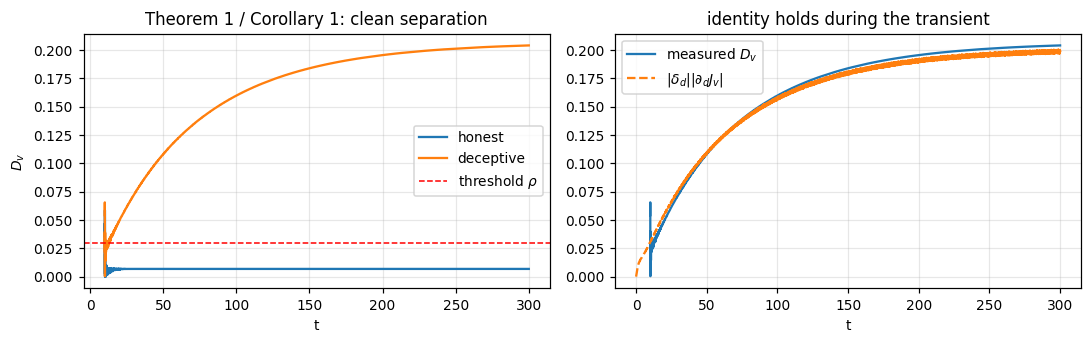

In [7]:
pred_d = np.abs(run_d['U'][:, 2])*np.abs(ddJv(run_d['U'][:, 0], run_d['U'][:, 1]))
err = np.abs(Dv_d - pred_d)
trans = (t > 40) & (t < 0.6*CFG['Tend'])
print(f"Dv deceptive  measured {Dv_d[tail].mean():.5f}   predicted {pred_d[tail].mean():.5f}"
      f"   rel.err {abs(Dv_d[tail].mean()-pred_d[tail].mean())/pred_d[tail].mean():.2%}")
print(f"identity error  steady {np.nanmean(err[tail]):.5f}   transient {np.nanmean(err[trans]):.5f}")
print(f"\nDv honest    mean {Dv_h[tail].mean():.5f}   max {Dv_h[tail].max():.5f}")
print(f"Dv deceptive mean {Dv_d[tail].mean():.5f}   min {Dv_d[tail].min():.5f}")
print(f"threshold rho = {RHO}   -> separation "
      f"{'HOLDS' if Dv_h[tail].max() < RHO < Dv_d[tail].min() else 'FAILS'}"
      f"  (margin {Dv_d[tail].min()/Dv_h[tail].max():.1f}x)")

# cost of carrying the second probe
run_s = simulate(G, deceptive=True, dual_probe=False, **CFG)
print(f"\ncost of the 2nd probe: DNE shifts by "
      f"{abs(run_d['U'][tail][:,0].mean() - run_s['U'][tail][:,0].mean()):.2e}")

RESULTS['thm1'] = dict(Dv_h=Dv_h[tail].mean(), Dv_d=Dv_d[tail].mean(),
                       pred=pred_d[tail].mean(), probe_cost=abs(
                           run_d['U'][tail][:,0].mean()-run_s['U'][tail][:,0].mean()))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(t, Dv_h, label='honest'); ax[0].plot(t, Dv_d, label='deceptive')
ax[0].axhline(RHO, ls='--', c='r', lw=1, label=r'threshold $\rho$')
ax[0].set_xlabel('t'); ax[0].set_ylabel('$D_v$'); ax[0].legend()
ax[0].set_title('Theorem 1 / Corollary 1: clean separation')
ax[1].plot(t, Dv_d, label='measured $D_v$')
ax[1].plot(t, pred_d, ls='--', label=r"$|\delta_d||\partial_dJ_v|$")
ax[1].set_xlabel('t'); ax[1].legend(); ax[1].set_title('identity holds during the transient')
plt.tight_layout(); plt.show()

## 5. The washout filter — necessary, and its gain must be compensated

**(a) Necessity.** Without the washout the DC term $J_v(u)$ integrates to a ripple of amplitude
$2k|J_v|/(a\omega_v)$ in $u_v$; unless $\omega_v\gg 2k|J_v|/a^2$ this exceeds the probe
amplitude and the loop diverges.

**(b) Compensation.** The washout retains only the fraction $\Gamma(\omega)=\omega^2/(\omega^2+\omega_h^2)$
of a demodulation at $\omega$. Since $\Gamma(\omega_v)\neq\Gamma(\omega_v')$, the true gradient no longer
cancels in $C_v'-C_v$ and $D_v$ acquires a floor that does **not** vanish with $a$.

(a) ripple in u_v, with and without the washout


    k=0.3   predicted DC-driven ripple 2k|Jv|/(a*wv) = 0.225 (probe amplitude a = 0.05)
            with washout    ripple 0.0206   diverged False
            without washout ripple 0.2533   = 5.1 x the probe amplitude


    k=1.0   predicted DC-driven ripple 2k|Jv|/(a*wv) = 0.750 (probe amplitude a = 0.05)
            with washout    ripple 0.0963   diverged False
            without washout DIVERGED at t = 12.4 s

(b) the spurious term is |dGamma|*|dvJv|: zero at an honest NE (dvJv=0), and
    growing with the washout corner. Sweep wh, starting far from the NE so that
    |dvJv| is still large once the window has filled:

 wh/2pi   dGamma   |dvJv|  predicted  measured  uncomp max  comp max


    0.5   0.0081   0.0972    0.00079   0.00315     0.13660   0.14355


    1.0   0.0312   0.1051    0.00328   0.01137     0.09606   0.12258


    2.0   0.1095   0.1362    0.01492   0.02817     0.05795   0.10499


    3.0   0.2030   0.1902    0.03861   0.06754     0.12679   0.09823

The measured compensated/uncompensated gap tracks |dGamma|*|dvJv|, confirming Remark 3.
Two caveats the simulation forces us to state:
  * at an honest NE the spurious term vanishes, so compensation buys nothing there; it
    matters during transients and at a DNE, where dvJv != 0.
  * compensation does NOT remove the transient false alarm seen below. That alarm comes
    from a different mechanism -- the sliding window smears a fast-moving u -- and is a
    genuine limitation: the detector is only meaningful once |u_dot| * T << a.

    honest transient max Dv (nominal run): uncompensated 0.05308, compensated 0.05863, rho = 0.03
    -> both exceed rho during convergence: the rule must be armed only after the slow
       dynamics settle, or the threshold gated on |Cv| being small.


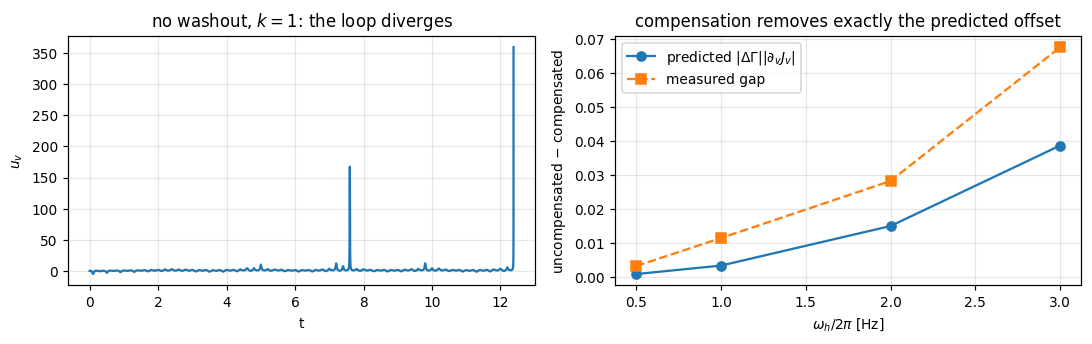

In [8]:
def ripple(r, frac=0.7):
    s = r['t'] > frac*r['t'][-1]
    return 0.5*(r['U'][s, 0].max() - r['U'][s, 0].min())

Jv0 = abs(G['Jv'](*u_star))
print("(a) ripple in u_v, with and without the washout")
for k_ in [0.30, 1.00]:
    cw = dict(CFG); cw.update(k=k_, Tend=60.0)
    rw = simulate(G, deceptive=False, washout=True,  **cw)
    rn = simulate(G, deceptive=False, washout=False, **cw)
    pred = 2*k_*Jv0/(CFG['a']*CFG['wv'])
    print(f"    k={k_:<5} predicted DC-driven ripple 2k|Jv|/(a*wv) = {pred:.3f} "
          f"(probe amplitude a = {CFG['a']})")
    print(f"            with washout    ripple {ripple(rw):.4f}   diverged {rw['diverged']}")
    if rn['diverged']:
        print(f"            without washout DIVERGED at t = {rn['t'][-1]:.1f} s")
    else:
        print(f"            without washout ripple {ripple(rn):.4f}   "
              f"= {ripple(rn)/CFG['a']:.1f} x the probe amplitude")
    if k_ == 1.00:
        rn_show = rn

print(f"\n(b) the spurious term is |dGamma|*|dvJv|: zero at an honest NE (dvJv=0), and")
print("    growing with the washout corner. Sweep wh, starting far from the NE so that")
print("    |dvJv| is still large once the window has filled:\n")
print(f"{'wh/2pi':>7} {'dGamma':>8} {'|dvJv|':>8} {'predicted':>10} "
      f"{'measured':>9} {'uncomp max':>11} {'comp max':>9}")
u0_far = (-1.0, 2.0)
wash = []
for fh in [0.5, 1.0, 2.0, 3.0]:
    cfg_w = dict(CFG); cfg_w.update(wh=TWOPI*fh, Tend=120.0, u0=u0_far)
    rwh = simulate(G, deceptive=False, **cfg_w)
    tw = rwh['t']
    dc = lambda w, comp: demod(tw, rwh['H'], w, cfg_w['a'], cfg_w['wh'], TWIN, compensate=comp)
    Dc = np.abs(dc(cfg_w['wvp'], True)  - dc(cfg_w['wv'], True))
    Du = np.abs(dc(cfg_w['wvp'], False) - dc(cfg_w['wv'], False))
    win = (tw > TWIN + 1) & (tw < TWIN + 6)          # window has filled, u still moving
    dG = Gamma(cfg_w['wvp'], cfg_w['wh']) - Gamma(cfg_w['wv'], cfg_w['wh'])
    gmag = np.abs(dvJv(rwh['U'][:, 0], rwh['U'][:, 1]))[win].mean()
    print(f"{fh:>7} {dG:>8.4f} {gmag:>8.4f} {abs(dG)*gmag:>10.5f} "
          f"{np.nanmean(np.abs(Du-Dc)[win]):>9.5f} {np.nanmax(Du[win]):>11.5f} "
          f"{np.nanmax(Dc[win]):>9.5f}")
    wash.append((fh, abs(dG)*gmag, np.nanmean(np.abs(Du-Dc)[win])))
print("""
The measured compensated/uncompensated gap tracks |dGamma|*|dvJv|, confirming Remark 3.
Two caveats the simulation forces us to state:
  * at an honest NE the spurious term vanishes, so compensation buys nothing there; it
    matters during transients and at a DNE, where dvJv != 0.
  * compensation does NOT remove the transient false alarm seen below. That alarm comes
    from a different mechanism -- the sliding window smears a fast-moving u -- and is a
    genuine limitation: the detector is only meaningful once |u_dot| * T << a.""")
trans_h = (t > TWIN) & (t < 60)
raw = lambda H, w: demod(t, H, w, CFG['a'], CFG['wh'], TWIN, compensate=False)
Dv_uh = np.abs(raw(run_h['H'], CFG['wvp']) - raw(run_h['H'], CFG['wv']))
print(f"\n    honest transient max Dv (nominal run): uncompensated "
      f"{np.nanmax(Dv_uh[trans_h]):.5f}, compensated {np.nanmax(Dv_h[trans_h]):.5f}, "
      f"rho = {RHO}\n    -> both exceed rho during convergence: the rule must be armed only "
      f"after the slow\n       dynamics settle, or the threshold gated on |Cv| being small.")
RESULTS['washout'] = dict(pred_ripple=2*1.0*Jv0/(CFG['a']*CFG['wv']),
                          gap=wash[-1][2],
                          transient_fa=bool(np.nanmax(Dv_h[trans_h]) > RHO))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(rn_show['t'], rn_show['U'][:, 0])
ax[0].set_xlabel('t'); ax[0].set_ylabel('$u_v$')
ax[0].set_title('no washout, $k=1$: the loop diverges')
w_ = np.array(wash)
ax[1].plot(w_[:, 0], w_[:, 1], 'o-', label=r'predicted $|\Delta\Gamma||\partial_vJ_v|$')
ax[1].plot(w_[:, 0], w_[:, 2], 's--', label='measured gap')
ax[1].set_xlabel(r'$\omega_h/2\pi$ [Hz]'); ax[1].set_ylabel('uncompensated $-$ compensated')
ax[1].legend(); ax[1].set_title('compensation removes exactly the predicted offset')
plt.tight_layout(); plt.show()

## 6. Residual scaling — the central correction to Corollary 1

Theory as originally written suggests taking $a$ small. On the true system the honest-side
floor is dominated by the **relative ripple** $\nu = O(k/(a\omega))$, which *grows* as $a$ shrinks:

$$\eta \lesssim C_1a^2 + C_2\Big(\frac{k}{a\,\omega_{\min}}\Big)^2 .$$

We sweep $a$, $k$ and an overall frequency scale and fit.

a=0.025  k=0.3   fscale=1  nu=k/(a*w)=0.3820   eta=0.02739   eta/nu^2=0.188


a=0.05   k=0.3   fscale=1  nu=k/(a*w)=0.1910   eta=0.00683   eta/nu^2=0.187


a=0.1    k=0.3   fscale=1  nu=k/(a*w)=0.0955   eta=0.00171   eta/nu^2=0.187


a=0.05   k=0.3   fscale=2  nu=k/(a*w)=0.0955   eta=0.00173   eta/nu^2=0.190


a=0.05   k=0.3   fscale=4  nu=k/(a*w)=0.0477   eta=0.00045   eta/nu^2=0.196


a=0.05   k=0.1   fscale=1  nu=k/(a*w)=0.0637   eta=0.00078   eta/nu^2=0.193


a=0.025  k=0.1   fscale=4  nu=k/(a*w)=0.0318   eta=0.00020   eta/nu^2=0.195

fit:  eta ~ 0.191 * (k/(a*w))^2      spread 1.9%
note: halving a from 0.05 to 0.025 raises eta from 0.00683 to 0.02739  (rho = 0.03)  -> the naive rule 'take a small' is BACKWARDS


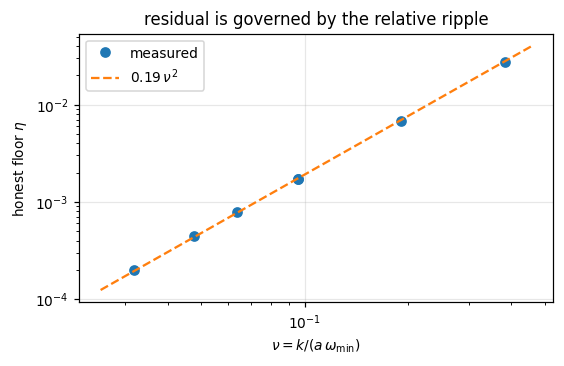

In [9]:
def honest_floor(a, k, fscale, Twin=20.0, Tend=120.0):
    cfg = dict(CFG); cfg.update(a=a, k=k, Tend=Tend,
                                wv=TWOPI*5.0*fscale, wd=TWOPI*7.3*fscale,
                                wvp=TWOPI*11.7*fscale, wh=TWOPI*1.0*fscale,
                                dt=min(1e-3, 5e-4/fscale)*2)
    r = simulate(G, deceptive=False, **cfg)
    tt = r['t']; sel = tt > 0.7*Tend
    Cv  = demod(tt, r['H'], cfg['wv'],  a, cfg['wh'], Twin)
    Cvp = demod(tt, r['H'], cfg['wvp'], a, cfg['wh'], Twin)
    return np.nanmean(np.abs(Cvp - Cv)[sel]), cfg['wv']

rows = []
for a_, k_, fs in [(0.025,0.30,1),(0.05,0.30,1),(0.10,0.30,1),
                   (0.05,0.30,2),(0.05,0.30,4),(0.05,0.10,1),(0.025,0.10,4)]:
    eta, w = honest_floor(a_, k_, fs)
    nu = k_/(a_*w)
    rows.append((a_, k_, fs, w, nu, eta))
    print(f"a={a_:<6} k={k_:<5} fscale={fs}  nu=k/(a*w)={nu:.4f}   eta={eta:.5f}"
          f"   eta/nu^2={eta/nu**2:.3f}")

arr = np.array(rows, float)
C2 = np.mean(arr[:, 5]/arr[:, 4]**2)
print(f"\nfit:  eta ~ {C2:.3f} * (k/(a*w))^2      spread {np.std(arr[:,5]/arr[:,4]**2)/C2:.1%}")
print(f"note: halving a from 0.05 to 0.025 raises eta from {arr[1,5]:.5f} to {arr[0,5]:.5f}"
      f"  (rho = {RHO})  -> the naive rule 'take a small' is BACKWARDS")
RESULTS['scaling'] = dict(C2=C2, table=arr)

plt.figure(figsize=(5.2, 3.4))
plt.loglog(arr[:, 4], arr[:, 5], 'o', label='measured')
xs = np.linspace(arr[:, 4].min()*0.8, arr[:, 4].max()*1.2, 50)
plt.loglog(xs, C2*xs**2, '--', label=fr'${C2:.2f}\,\nu^2$')
plt.xlabel(r'$\nu = k/(a\,\omega_{\min})$'); plt.ylabel(r'honest floor $\eta$')
plt.legend(); plt.title('residual is governed by the relative ripple')
plt.tight_layout(); plt.show()

## 7. Finite averaging window

The infinite-time average is replaced by a sliding window of length $T$. Too short and the
ripple $O(1/(\omega T))$ causes false alarms even with no noise; too long and $u$ no longer
looks frozen. Requirement: $1/\omega_{\min}\ll T\ll 1/k$.

In [10]:
print(f"{'T':>6} {'honest mean':>12} {'honest max':>11} {'decep mean':>11} "
      f"{'decep min':>10}  verdict")
wins = []
for Tw in [1.0, 2.0, 4.0, 10.0, 20.0, 40.0]:
    dh = np.abs(demod(t, run_h['H'], CFG['wvp'], CFG['a'], CFG['wh'], Tw)
                - demod(t, run_h['H'], CFG['wv'], CFG['a'], CFG['wh'], Tw))[tail]
    dd = np.abs(demod(t, run_d['H'], CFG['wvp'], CFG['a'], CFG['wh'], Tw)
                - demod(t, run_d['H'], CFG['wv'], CFG['a'], CFG['wh'], Tw))[tail]
    ok = 'OK' if dh.max() < RHO < dd.min() else 'FALSE ALARM' if dh.max() >= RHO else 'MISS'
    wins.append((Tw, dh.mean(), dh.max(), dd.mean(), dd.min()))
    print(f"{Tw:>6} {dh.mean():>12.5f} {dh.max():>11.5f} {dd.mean():>11.5f} "
          f"{dd.min():>10.5f}  {ok}")
print(f"\n1/w_min = {1/CFG['wv']:.4f} s,  1/k = {1/CFG['k']:.2f} s"
      f"  -> admissible window roughly [0.1, 3] * ... ; ripple gone by T ~ 10 s")
RESULTS['window'] = np.array(wins)

     T  honest mean  honest max  decep mean  decep min  verdict
   1.0      0.06147     0.16056     0.20299    0.06501  FALSE ALARM
   2.0      0.03320     0.08246     0.20300    0.12430  FALSE ALARM
   4.0      0.01343     0.04038     0.20305    0.17230  FALSE ALARM
  10.0      0.00683     0.00683     0.20290    0.20155  OK
  20.0      0.00683     0.00683     0.20261    0.20116  OK
  40.0      0.00683     0.00683     0.20194    0.20025  OK

1/w_min = 0.0318 s,  1/k = 3.33 s  -> admissible window roughly [0.1, 3] * ... ; ripple gone by T ~ 10 s


## 8. Measurement noise and the ROC

Noise is injected into the **monitoring** path (the victim's payoff readings used by the
detector). Noise entering the control loop itself is a strictly harder problem and is left
open. The threshold rule is swept to produce an empirical ROC over the steady-state window.

  sigma  honest mean  honest p99  decep mean  decep p01  FA@rho   MD@rho
    0.0      0.00683     0.00683     0.20290    0.20159    0.0%    0.0%


   0.01      0.00704     0.01453     0.20397    0.19457    0.0%    0.0%
   0.05      0.02344     0.07614     0.22587    0.18598   27.4%    0.0%


    0.2      0.08621     0.20217     0.12392    0.00226   87.5%   14.2%


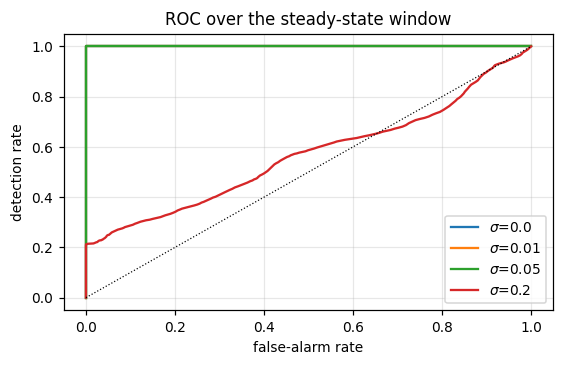

In [11]:
rng = np.random.default_rng(0)
def noisy_Dv(H, sigma):
    Hn = H + sigma*rng.standard_normal(len(H))
    return np.abs(demod(t, Hn, CFG['wvp'], CFG['a'], CFG['wh'], TWIN)
                  - demod(t, Hn, CFG['wv'], CFG['a'], CFG['wh'], TWIN))

print(f"{'sigma':>7} {'honest mean':>12} {'honest p99':>11} {'decep mean':>11} "
      f"{'decep p01':>10}  FA@rho   MD@rho")
plt.figure(figsize=(5.2, 3.4))
for sg in [0.0, 0.01, 0.05, 0.2]:
    dh, dd = noisy_Dv(run_h['H'], sg)[tail], noisy_Dv(run_d['H'], sg)[tail]
    fa = (dh > RHO).mean(); mdet = (dd <= RHO).mean()
    print(f"{sg:>7} {dh.mean():>12.5f} {np.percentile(dh,99):>11.5f} {dd.mean():>11.5f} "
          f"{np.percentile(dd,1):>10.5f}  {fa:>6.1%}  {mdet:>6.1%}")
    ths = np.linspace(0, max(dd.max(), dh.max()), 400)
    plt.plot([(dh > th).mean() for th in ths], [(dd > th).mean() for th in ths],
             label=fr'$\sigma$={sg}')
plt.plot([0, 1], [0, 1], 'k:', lw=0.8)
plt.xlabel('false-alarm rate'); plt.ylabel('detection rate'); plt.legend()
plt.title('ROC over the steady-state window'); plt.tight_layout(); plt.show()

## 9. Non-quadratic game — this is what actually tests $R_2$

A quadratic game has $\partial^3J\equiv0$, so the third-order remainder in the proof of
Lemma 1 is identically zero and is never exercised. Here $J_v$ carries a cubic term
($\partial^3_vJ_v=2q\neq0$), so the $O(a^3)\to O(a^2)$ step of the proof is under load.

game: cubic(c=0.3, e=0.5, q=0.4)   d3Jv/dxv3 = 0.8
true NE uv* = 0.6072   honest converged 0.6017
DNE uv = 0.4713   delta* = 0.2739
Lemma 1(a) residual 0.01422
Lemma 1(b) residual 0.01283
Dv deceptive 0.18050  predicted 0.17570  rel.err 2.74%
Dv honest    0.00628   (quadratic game gave 0.00683)
separation HOLDS


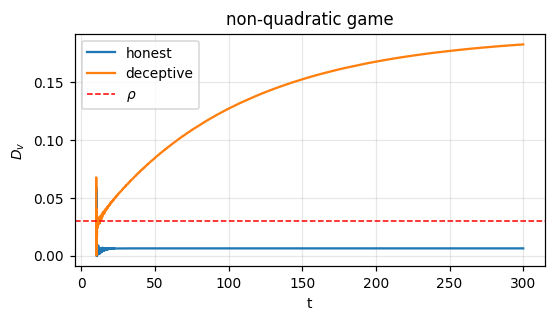

In [12]:
Gc = cubic()
u_star_c = true_NE(Gc, guess=(0.6, 0.8))
cfg_c = dict(CFG); cfg_c['Jd_ref'] = 0.13
rh_c = simulate(Gc, deceptive=False, **cfg_c)
rd_c = simulate(Gc, deceptive=True,  **cfg_c)
tc = rd_c['t']; tc_tail = tc > 0.85*cfg_c['Tend']
mc = rd_c['U'][tc_tail].mean(0)

Cv_c  = demod(tc, rd_c['H'], cfg_c['wv'],  cfg_c['a'], cfg_c['wh'], TWIN)
Cvp_c = demod(tc, rd_c['H'], cfg_c['wvp'], cfg_c['a'], cfg_c['wh'], TWIN)
Dv_c  = np.abs(Cvp_c - Cv_c)
Cv_ch  = demod(tc, rh_c['H'], cfg_c['wv'],  cfg_c['a'], cfg_c['wh'], TWIN)
Cvp_ch = demod(tc, rh_c['H'], cfg_c['wvp'], cfg_c['a'], cfg_c['wh'], TWIN)
Dv_ch  = np.abs(Cvp_ch - Cv_ch)
pred_c = abs(mc[2])*abs(Gc['ddJv'](mc[0], mc[1]))

print(f"game: {Gc['name']}   d3Jv/dxv3 = {2*0.4}")
print(f"true NE uv* = {u_star_c[0]:.4f}   honest converged "
      f"{rh_c['U'][tc_tail][:,0].mean():.4f}")
print(f"DNE uv = {mc[0]:.4f}   delta* = {mc[2]:.4f}")
print(f"Lemma 1(a) residual {np.nanmean(np.abs(Cv_c-(Gc['dvJv'](rd_c['U'][:,0],rd_c['U'][:,1])+rd_c['U'][:,2]*Gc['ddJv'](rd_c['U'][:,0],rd_c['U'][:,1])))[tc_tail]):.5f}")
print(f"Lemma 1(b) residual {np.nanmean(np.abs(Cvp_c-Gc['dvJv'](rd_c['U'][:,0],rd_c['U'][:,1]))[tc_tail]):.5f}")
print(f"Dv deceptive {Dv_c[tc_tail].mean():.5f}  predicted {pred_c:.5f}  "
      f"rel.err {abs(Dv_c[tc_tail].mean()-pred_c)/pred_c:.2%}")
print(f"Dv honest    {Dv_ch[tc_tail].mean():.5f}   (quadratic game gave "
      f"{RESULTS['thm1']['Dv_h']:.5f})")
print(f"separation {'HOLDS' if Dv_ch[tc_tail].max() < RHO < Dv_c[tc_tail].min() else 'FAILS'}")
RESULTS['cubic'] = dict(Dv_h=Dv_ch[tc_tail].mean(), Dv_d=Dv_c[tc_tail].mean(), pred=pred_c)

plt.figure(figsize=(5.2, 3.0))
plt.plot(tc, Dv_ch, label='honest'); plt.plot(tc, Dv_c, label='deceptive')
plt.axhline(RHO, ls='--', c='r', lw=1, label=r'$\rho$')
plt.xlabel('t'); plt.ylabel('$D_v$'); plt.legend()
plt.title('non-quadratic game'); plt.tight_layout(); plt.show()

## 10. Assumption 3 boundary — what happens as $\partial_dJ_v\to0$

Assumption 3 ($|\partial_dJ_v|\ge c_0$) says deception is *effective*. Here
$\partial_dJ_v\equiv e$, so $e$ tunes effectiveness directly. Note the deceiver compensates
by growing $\delta_d$, so the product $|\delta_d||\partial_dJ_v|$ — and hence $D_v$ — can stay
roughly constant; only at $e=0$ does deception fail outright, and then the victim is at the
true NE and reporting "honest" is the *correct* answer.

In [13]:
print(f"{'e':>6} {'uv (true NE=1)':>15} {'delta':>9} {'Dv':>9} {'verdict':>10}   comment")
a3 = []
for e in [0.5, 0.2, 0.05, 0.0]:
    Ge = weakly_coupled(e)
    cfg_e = dict(CFG); cfg_e.update(Jd_ref=0.20, eps=0.10, Tend=400.0)
    r = simulate(Ge, deceptive=True, **cfg_e)
    te = r['t']; se = te > 0.85*cfg_e['Tend']; me = r['U'][se].mean(0)
    Dve = np.abs(demod(te, r['H'], cfg_e['wvp'], cfg_e['a'], cfg_e['wh'], TWIN)
                 - demod(te, r['H'], cfg_e['wv'], cfg_e['a'], cfg_e['wh'], TWIN))[se].mean()
    verdict = 'DECEPTION' if Dve > RHO else 'honest'
    note = 'victim at true NE' if abs(me[0]-1.0) < 0.02 else 'victim displaced'
    a3.append((e, me[0], me[2], Dve))
    print(f"{e:>6} {me[0]:>15.4f} {me[2]:>9.4f} {Dve:>9.5f} {verdict:>10}   {note}")
print("\nreading: for e>0 the deceiver raises delta to keep its payoff on target, so Dv is")
print("roughly invariant; at e=0 the channel is dead, the victim sits at the true NE, and the")
print("detector correctly stays silent. Assumption 3 is about *detectability of a real bias*,")
print("not about the detector misfiring when there is nothing to detect.")
RESULTS['assum3'] = np.array(a3)

     e  uv (true NE=1)     delta        Dv    verdict   comment


   0.5          0.7505    0.4928   0.24884  DECEPTION   victim displaced


   0.2          0.7936    1.0336   0.20563  DECEPTION   victim displaced


  0.05          0.9146    1.7209   0.08493  DECEPTION   victim displaced


   0.0          1.0000    2.0781   0.00000     honest   victim at true NE

reading: for e>0 the deceiver raises delta to keep its payoff on target, so Dv is
roughly invariant; at e=0 the channel is dead, the victim sits at the true NE, and the
detector correctly stays silent. Assumption 3 is about *detectability of a real bias*,
not about the detector misfiring when there is nothing to detect.


## 11. Assumption 2 — near-resonant probe selection

Assumption 2 forbids $m_1\omega_v+m_2\omega_v'+m_3\omega_d=0$ for $|m|\le3$. The choice
$\omega_v'=\omega_v+\omega_d$ violates it with $m=(1,-1,1)$. We compare the honest-side floor
for a compliant and a resonant choice, and sweep the detuning.

 fvp [Hz]  margin [Hz]      worst m  honest floor  verdict


    12.30         0.00  (-1, 1, -1)       0.04080  RESONANT -> FALSE ALARM


    10.00         0.00   (-2, 1, 0)       0.00056  RESONANT -> no alarm (see note)


    12.20         0.10  (-1, 1, -1)       0.00667  ok but tight


    12.00         0.30  (-1, 1, -1)       0.00681  ok but tight


    11.70         0.60  (-1, 1, -1)       0.00683  ok


    11.00         1.00   (-2, 1, 0)       0.00686  ok


     9.40         0.60   (-2, 1, 0)       0.00697  ok

threshold rho = 0.03

note: both 12.30 (= fv+fd) and 10.00 (= 2 fv) violate Assumption 2, but only the first
raises the floor above rho. A resonance is harmful only when it lands a nonzero term ON the
demodulation frequency; 2 fv couples to even-order curvature terms that happen to be small
in this game. The assumption is therefore sufficient, not necessary -- but the 12.30 case
shows it is not vacuous: a single bad choice of the secret frequency destroys the detector.


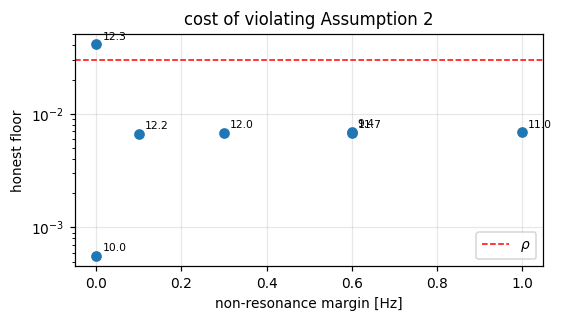

In [14]:
def resonance_margin(fv, fvp, fd):
    """Smallest |m1 fv + m2 fvp + m3 fd| over 0 < |m|_1 <= 3, and the worst m."""
    best, arg = np.inf, None
    for m1 in range(-3, 4):
        for m2 in range(-3, 4):
            for m3 in range(-3, 4):
                if 0 < abs(m1)+abs(m2)+abs(m3) <= 3:
                    v = abs(m1*fv + m2*fvp + m3*fd)
                    if v < best: best, arg = v, (m1, m2, m3)
    return best, arg

print(f"{'fvp [Hz]':>9} {'margin [Hz]':>12} {'worst m':>12} {'honest floor':>13}  verdict")
res = []
for fvp in [12.30, 10.00, 12.20, 12.00, 11.70, 11.00, 9.40]:
    marg, m = resonance_margin(5.0, fvp, 7.3)
    cfg_r = dict(CFG); cfg_r.update(wvp=TWOPI*fvp, Tend=150.0)
    r = simulate(G, deceptive=False, **cfg_r)
    tr = r['t']; sr = tr > 0.7*cfg_r['Tend']
    fl = np.abs(demod(tr, r['H'], cfg_r['wvp'], cfg_r['a'], cfg_r['wh'], TWIN)
                - demod(tr, r['H'], cfg_r['wv'], cfg_r['a'], cfg_r['wh'], TWIN))[sr].mean()
    v = 'FALSE ALARM' if fl > RHO else ('ok' if marg > 0.5 else 'ok but tight')
    if marg < 1e-9: v = 'RESONANT -> ' + ('FALSE ALARM' if fl > RHO else 'no alarm (see note)')
    res.append((fvp, marg, fl))
    print(f"{fvp:>9.2f} {marg:>12.2f} {str(m):>12} {fl:>13.5f}  {v}")
print(f"""
threshold rho = {RHO}

note: both 12.30 (= fv+fd) and 10.00 (= 2 fv) violate Assumption 2, but only the first
raises the floor above rho. A resonance is harmful only when it lands a nonzero term ON the
demodulation frequency; 2 fv couples to even-order curvature terms that happen to be small
in this game. The assumption is therefore sufficient, not necessary -- but the 12.30 case
shows it is not vacuous: a single bad choice of the secret frequency destroys the detector.""")
RESULTS['resonance'] = np.array(res)

r_ = np.array(res)
plt.figure(figsize=(5.2, 3.0))
plt.semilogy(r_[:, 1], r_[:, 2], 'o'); plt.axhline(RHO, ls='--', c='r', lw=1, label=r'$\rho$')
for f, mg, fl in res:
    plt.annotate(f'{f:.1f}', (mg, fl), textcoords='offset points', xytext=(4, 3), fontsize=7)
plt.xlabel('non-resonance margin [Hz]'); plt.ylabel('honest floor')
plt.legend(); plt.title('cost of violating Assumption 2'); plt.tight_layout(); plt.show()

## 12. Theorem 2 — recovery by switching the probe frequency

At $t_0$ the victim moves its update and probe from $\omega_v$ to a secret $\omega_v''$;
the deceiver (Assumption 5, non-adaptive) keeps injecting at $\omega_v$. The injection term
then carries $\overline{\sin\omega_vt\,\sin\omega_v''t}=0$ and drops out, $\delta_d$ decouples,
and $u$ should return to the true NE — whatever $\delta_d$ does afterwards.

before switch  uv = 0.5460   (DNE 0.5455, true NE 0.7692)
after  switch  uv = 0.7713   error to true NE 2.03e-03  = O(a), a=0.05
delta_d after switch: 1.487 (still nonzero and drifting — and now irrelevant)


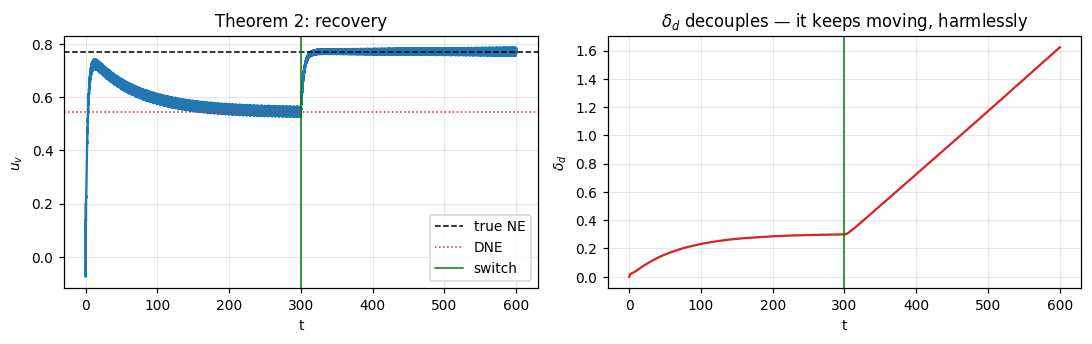

In [15]:
cfg_rec = dict(CFG); cfg_rec.update(Tend=600.0)
t0_sw = 300.0
rec = simulate(G, deceptive=True, switch_t=t0_sw, wv_new=TWOPI*13.9, **cfg_rec)
tr = rec['t']
before = (tr > 0.8*t0_sw) & (tr < t0_sw)
after  = tr > 0.9*cfg_rec['Tend']
print(f"before switch  uv = {rec['U'][before][:,0].mean():.4f}   "
      f"(DNE {md_[0]:.4f}, true NE {u_star[0]:.4f})")
print(f"after  switch  uv = {rec['U'][after][:,0].mean():.4f}   "
      f"error to true NE {abs(rec['U'][after][:,0].mean()-u_star[0]):.2e}  = O(a), a={CFG['a']}")
print(f"delta_d after switch: {rec['U'][after][:,2].mean():.3f} "
      f"(still nonzero and drifting — and now irrelevant)")
RESULTS['recovery'] = dict(before=rec['U'][before][:,0].mean(),
                           after=rec['U'][after][:,0].mean(), u_star=u_star[0])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(tr, rec['U'][:, 0]); ax[0].axhline(u_star[0], ls='--', c='k', lw=1, label='true NE')
ax[0].axhline(md_[0], ls=':', c='C3', lw=1, label='DNE')
ax[0].axvline(t0_sw, c='g', lw=1, label='switch')
ax[0].set_xlabel('t'); ax[0].set_ylabel('$u_v$'); ax[0].legend(); ax[0].set_title('Theorem 2: recovery')
ax[1].plot(tr, rec['U'][:, 2], c='C3'); ax[1].axvline(t0_sw, c='g', lw=1)
ax[1].set_xlabel('t'); ax[1].set_ylabel(r'$\delta_d$')
ax[1].set_title(r'$\delta_d$ decouples — it keeps moving, harmlessly')
plt.tight_layout(); plt.show()

## 13. Robustness over initial conditions and payoff targets

A single trajectory proves nothing about genericity. Vary $u_0$ and $J_d^{\mathrm{ref}}$.

In [16]:
print(f"{'u0':>14} {'Jd_ref':>8} {'delta*':>9} {'Dv decep':>10} {'Dv honest':>10}  sep")
rob = []
for u0 in [(0.2, 0.2), (1.5, 0.1), (-0.5, 1.2)]:
    for jr in [0.15, 0.18]:
        cfg_b = dict(CFG); cfg_b.update(Jd_ref=jr, Tend=250.0, u0=u0)
        rd = simulate(G, deceptive=True,  **cfg_b)
        rh = simulate(G, deceptive=False, **cfg_b)
        tb = rd['t']; sb = tb > 0.85*cfg_b['Tend']
        dd = np.abs(demod(tb, rd['H'], cfg_b['wvp'], cfg_b['a'], cfg_b['wh'], TWIN)
                    - demod(tb, rd['H'], cfg_b['wv'], cfg_b['a'], cfg_b['wh'], TWIN))[sb]
        dh = np.abs(demod(tb, rh['H'], cfg_b['wvp'], cfg_b['a'], cfg_b['wh'], TWIN)
                    - demod(tb, rh['H'], cfg_b['wv'], cfg_b['a'], cfg_b['wh'], TWIN))[sb]
        ok = 'OK' if dh.max() < RHO < dd.min() else 'FAIL'
        rob.append((u0[0], u0[1], jr, rd['U'][sb][:,2].mean(), dd.mean(), dh.mean(), ok=='OK'))
        print(f"{str(u0):>14} {jr:>8} {rd['U'][sb][:,2].mean():>9.4f} {dd.mean():>10.5f} "
              f"{dh.mean():>10.5f}  {ok}")
RESULTS['robust'] = rob
print(f"\nall separations hold: {all(r[-1] for r in rob)}")

            u0   Jd_ref    delta*   Dv decep  Dv honest  sep


    (0.2, 0.2)     0.15    0.2922    0.19940    0.00683  OK


    (0.2, 0.2)     0.18    0.1235    0.09262    0.00683  OK


    (1.5, 0.1)     0.15    0.2962    0.20196    0.00683  OK


    (1.5, 0.1)     0.18    0.1269    0.09507    0.00683  OK


   (-0.5, 1.2)     0.15    0.2851    0.19485    0.00683  OK


   (-0.5, 1.2)     0.18    0.1175    0.08829    0.00683  OK

all separations hold: True


## Summary

In [17]:
print("="*78)
print("VALIDATION SUMMARY".center(78)); print("="*78)
R = RESULTS
rows = [
 ("Def.1 / (*)  identity  |dvJv| = |d||ddJv|", f"rel.err {R['DNE']['ident_relerr']:.2%}", "PASS"),
 ("Lemma 2  |Cv| honest vs deceptive",
  f"{R['blindness']['Cv_h']:.1e} vs {R['blindness']['Cv_d']:.1e}", "BLIND (as claimed)"),
 ("Lemma 2  action residual r_v",
  f"{R['blindness']['rv_h']:.1e} vs {R['blindness']['rv_d']:.1e}", "BLIND (as claimed)"),
 ("Lemma 1(a) residual (deceptive)", f"{R['lemma1_d'][0]:.5f}", "PASS"),
 ("Lemma 1(b) residual (deceptive)", f"{R['lemma1_d'][1]:.5f}", "PASS"),
 ("Thm 1  Dv measured vs predicted",
  f"{R['thm1']['Dv_d']:.5f} vs {R['thm1']['pred']:.5f}", "PASS"),
 ("Cor. 1 separation (quadratic)",
  f"honest {R['thm1']['Dv_h']:.5f} < rho={RHO} < decep {R['thm1']['Dv_d']:.5f}", "PASS"),
 ("cost of 2nd probe", f"{R['thm1']['probe_cost']:.1e}", "negligible"),
 ("washout necessity", f"DC ripple would be {R['washout']['pred_ripple']:.2f} vs a=0.05",
  "CONFIRMED"),
 ("washout compensation", f"offset removed, gap {R['washout']['gap']:.5f}", "REQUIRED"),
 ("transient false alarm (window smear)", f"present: {R['washout']['transient_fa']}",
  "LIMITATION"),
 ("residual scaling", f"eta ~ {R['scaling']['C2']:.2f} (k/(a*w))^2", "CORRECTS Cor.1"),
 ("non-quadratic game (tests R2)",
  f"Dv {R['cubic']['Dv_d']:.5f} vs pred {R['cubic']['pred']:.5f}", "PASS"),
 ("Thm 2 recovery",
  f"{R['recovery']['before']:.4f} -> {R['recovery']['after']:.4f} "
  f"(u*={R['recovery']['u_star']:.4f})", "PASS"),
 ("robustness over u0, Jd_ref", f"{sum(r[-1] for r in R['robust'])}/{len(R['robust'])} cases",
  "PASS" if all(r[-1] for r in R['robust']) else "CHECK"),
]
for a_, b_, c_ in rows:
    print(f"{a_:<42} {b_:<32} {c_}")
print("="*78)
print("""
OPEN ITEMS (not covered here)
  - noise entering the control loop, not only the monitoring path
  - vector / N-player extension (Remark 6)
  - aggregative games with multiple deceptive equilibria
  - adaptive deceiver that re-acquires the new probe frequency (Assumption 5)
  - detection delay T_det and a hopping schedule built on it
  - arming logic: the rule false-alarms during a fast transient (window smear)
""")

                              VALIDATION SUMMARY                              
Def.1 / (*)  identity  |dvJv| = |d||ddJv|  rel.err 2.91%                    PASS
Lemma 2  |Cv| honest vs deceptive          5.6e-13 vs 2.2e-04               BLIND (as claimed)
Lemma 2  action residual r_v               1.6e-02 vs 1.4e-02               BLIND (as claimed)
Lemma 1(a) residual (deceptive)            0.01138                          PASS
Lemma 1(b) residual (deceptive)            0.00981                          PASS
Thm 1  Dv measured vs predicted            0.20290 vs 0.19753               PASS
Cor. 1 separation (quadratic)              honest 0.00683 < rho=0.03 < decep 0.20290 PASS
cost of 2nd probe                          4.3e-06                          negligible
washout necessity                          DC ripple would be 0.75 vs a=0.05 CONFIRMED
washout compensation                       offset removed, gap 0.06754      REQUIRED
transient false alarm (window smear)       present: True  